# P22 – Sleep Disorder Detector
**Name:** AKSHA MANSURI
**Roll No.:** H30
**Enrollment No.:** 24004501210183
**Division:** E

**Problem:** Predict sleep disorder (None / Insomnia / Sleep Apnea) from sleep duration, sleep quality, physical activity, stress level, BMI category, blood pressure, heart rate and daily steps.
**Dataset:** https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset
**Target (Y):** Sleep Disorder (3 classes)
**Model:** Naïve Bayes (GaussianNB)
**Main metric:** Macro F1

## Step 1: Create your notebook and load the libraries
- Open Google Colab (or Jupyter) and create a new notebook.
- Rename it as RollNo_P22_Name.ipynb (example: H35_P22_Riya.ipynb).
- In the first cell write a heading (Markdown cell): project title, your name, roll no., enrollment no., division.
- Write a code cell that imports all the libraries and your model, then run it.

In [1]:
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


# P22 – Sleep Disorder Detector

**Project Title:** Sleep Disorder Detector Using Gaussian Naïve Bayes

**Student Name:** Aksha Mansuri
**Roll Number:** H30
**Division:** E
**Enrollment Number:** 24004501210183
**University:** LJ University

**Objective:** To predict whether a person belongs to the None, Insomnia, or Sleep Apnea category using sleep habits and lifestyle information.

**Machine Learning Algorithm:** Gaussian Naïve Bayes (GaussianNB)

**Problem Type:** Multiclass Classification

**Main Evaluation Metric:** Macro F1 Score


## Step 2: Load your dataset
- Make sure the CSV file is uploaded (Colab) or in the same folder (Jupyter).
- Load the file and print the number of rows and columns, and the first 5 rows.

In [22]:
# Step 2: Load the dataset

df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
print("\nFirst five rows of the dataset:")
display(df.head())

Dataset shape: (374, 13)

First five rows of the dataset:


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


### Dataset Description

I used the Sleep Health and Lifestyle dataset downloaded from Kaggle.

**Dataset source:** Sleep Health and Lifestyle Dataset

The original dataset contains **374 rows and 13 columns**. Each row represents a person's sleep and lifestyle information, including age, occupation, sleep duration, quality of sleep, physical activity, stress level, BMI category, blood pressure, heart rate, daily steps, and sleep disorder.

The target column is `Sleep Disorder`, which the model uses to predict one of three categories: None, Insomnia, or Sleep Apnea.


## Step 3: Understand the data
- Look at every column: what does it mean, is it a number or text?
- Check missing values and the target classes.
- Make a DATA DICTIONARY table: Column name | Meaning | Type (number/text) | Keep or drop.

In [23]:
# Step 3: Understand the dataset

# Display column names, data types, and non-null values
print("Dataset information:")
df.info()

# Display statistical information about numerical columns
print("\nStatistical summary:")
display(df.describe())

# Display the first five rows
print("\nFirst five rows:")
display(df.head())

# Check missing values in each column
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check the target column
print("\nSleep Disorder categories:")
print(df["Sleep Disorder"].value_counts(dropna=False))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 38.1 KB

Statistical sum

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000



First five rows:


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea



Missing values in each column:
Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64

Number of duplicate rows:
0

Sleep Disorder categories:
Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


### Data Dictionary

| Column name             | Meaning                                      | Type           | Keep or drop                   |
| ----------------------- | -------------------------------------------- | -------------- | ------------------------------ |
| Person ID               | Unique identification number for each person | Number         | Drop                           |
| Gender                  | Gender recorded in the dataset               | Text           | Keep                           |
| Age                     | Age of the person                            | Number         | Keep                           |
| Occupation              | Person's occupation                          | Text           | Keep                           |
| Sleep Duration          | Average hours of sleep                       | Number         | Keep                           |
| Quality of Sleep        | Sleep quality score                          | Number         | Keep                           |
| Physical Activity Level | Daily physical activity level                | Number         | Keep                           |
| Stress Level            | Recorded stress score                        | Number         | Keep                           |
| BMI Category            | Body mass index category                     | Text           | Keep                           |
| Blood Pressure          | Systolic and diastolic blood pressure        | Text initially | Split into two numeric columns |
| Heart Rate              | Heart rate in beats per minute               | Number         | Keep                           |
| Daily Steps             | Number of steps taken per day                | Number         | Keep                           |
| Sleep Disorder          | Sleep disorder category                      | Text           | Keep as target                 |


I checked the dataset using `df.info()`, `df.describe()`, `df.isnull().sum()`, and `df.duplicated().sum()`.

The dataset contains both numerical and categorical columns. I found missing values in the Sleep Disorder column, while the dataset had no duplicate rows. I also noticed that Blood Pressure was stored as text and that BMI Category contained both Normal and Normal Weight labels.


## Step 4: Prepare the target column (Y)
- Your target (what the model predicts) is: Sleep Disorder (3 classes).
- The target already exists in the data. Just check how many rows each class has.
- If one class is much bigger than others, the data is IMBALANCED. Write this down: it affects which metric you trust.

In [24]:
# Step 4: Check the target class distribution

# Count records in each sleep disorder category
class_counts = df["Sleep Disorder"].value_counts(dropna=False)

print("Number of records in each category:")
print(class_counts)

# Calculate the percentage of each category
class_percentages = df["Sleep Disorder"].value_counts(
    normalize=True, dropna=False
) * 100

print("\nPercentage of records in each category:")
print(class_percentages.round(2))

# Display count and percentage together
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("\nTarget Class Distribution Table:")
display(class_distribution)

Number of records in each category:
Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Percentage of records in each category:
Sleep Disorder
NaN            58.56
Sleep Apnea    20.86
Insomnia       20.59
Name: proportion, dtype: float64

Target Class Distribution Table:


,Count,Percentage (%)
Sleep Disorder,,
NaN,219,58.56
Sleep Apnea,78,20.86
Insomnia,77,20.59


### Target Column: Sleep Disorder

The target column contains three classes:

| Class       | Number of records |
| ----------- | ----------------: |
| None        |               219 |
| Insomnia    |                77 |
| Sleep Apnea |                78 |
| **Total**   |           **374** |

The target classes are imbalanced because the None category has considerably more records than Insomnia and Sleep Apnea.

Therefore, I used **Macro F1 Score** as the main evaluation metric because it gives equal importance to each class instead of allowing the largest class to dominate the result.


## Step 5: Clean the data
- Remove duplicate rows.
- Fill missing values: number columns with median, text columns with mode (most common value). Or drop a column if most of it is empty.
- Drop ID / name columns and any column that gives away the answer (leakage).
- Special note for YOUR dataset: pandas reads the text 'None' as missing: use keep_default_na=False or fill it back to 'None'. Split Blood Pressure '126/83' into two numeric columns. BMI Category has 'Normal' and 'Normal Weight': merge them.

In [25]:
# Step 5: Clean the dataset

# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# 1. Remove duplicate rows
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

print("Duplicate rows removed:", duplicates_before)

# 2. Handle missing values in the target column
# Missing target values are treated as the "None" category,
# following the dataset-label convention described in the guide.
df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")

print("\nMissing target values filled with 'None'.")

# 3. Split Blood Pressure into two numerical columns
# Example: 126/83 becomes Systolic BP = 126 and Diastolic BP = 83
df_clean[["Systolic BP", "Diastolic BP"]] = (
    df_clean["Blood Pressure"]
    .str.split("/", expand=True)
    .astype(float)
)

print("Blood Pressure split into Systolic BP and Diastolic BP.")

# 4. Merge similar BMI categories
df_clean["BMI Category"] = df_clean["BMI Category"].replace(
    "Normal Weight", "Normal"
)

print("BMI categories 'Normal Weight' and 'Normal' merged.")

# 5. Remove unnecessary columns
# Person ID is an identifier, not a useful predictive feature.
# Blood Pressure is removed because its numerical components
# have already been extracted into separate columns.
df_clean = df_clean.drop(
    columns=["Person ID", "Blood Pressure"]
)

print("Removed Person ID and the original Blood Pressure column.")

# 6. Fill any remaining missing values
# Numerical columns: fill with median.
# Text columns: fill with the most common value (mode).
# Sleep Disorder is excluded because its missing values were
# handled separately above.
for column in df_clean.columns:

    if column == "Sleep Disorder":
        continue

    if df_clean[column].isnull().any():

        if pd.api.types.is_numeric_dtype(df_clean[column]):
            df_clean[column] = df_clean[column].fillna(
                df_clean[column].median()
            )

        else:
            mode_values = df_clean[column].mode()

            if not mode_values.empty:
                df_clean[column] = df_clean[column].fillna(
                    mode_values[0]
                )

# 7. Display the cleaning results
print("\n--- Data Cleaning Results ---")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values in each column:")
print(df_clean.isnull().sum())

print("\nTotal missing values remaining:", df_clean.isnull().sum().sum())

print("\nDuplicate rows remaining:", df_clean.duplicated().sum())

print("\nSleep Disorder categories after cleaning:")
print(df_clean["Sleep Disorder"].value_counts())

print("\nBMI Category values after cleaning:")
print(df_clean["BMI Category"].value_counts())

print("\nFirst five rows of the cleaned dataset:")
display(df_clean.head())

Duplicate rows removed: 0

Missing target values filled with 'None'.
Blood Pressure split into Systolic BP and Diastolic BP.
BMI categories 'Normal Weight' and 'Normal' merged.
Removed Person ID and the original Blood Pressure column.

--- Data Cleaning Results ---
Original dataset shape: (374, 13)
Cleaned dataset shape: (374, 13)

Missing values in each column:
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
Systolic BP                0
Diastolic BP               0
dtype: int64

Total missing values remaining: 0

Duplicate rows remaining: 242

Sleep Disorder categories after cleaning:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

BMI Category values after cleaning:
B

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic BP,Diastolic BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126.0,83.0
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125.0,80.0
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125.0,80.0
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140.0,90.0
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140.0,90.0


### Data Cleaning

I cleaned the dataset before training the model.

1. **Removed duplicate rows:** I used `drop_duplicates()` to avoid repeated records.
2. **Handled missing target values:** I filled missing values in `Sleep Disorder` with `"None"` to preserve the records and follow the project's chosen labeling assumption.
3. **Handled missing numerical values:** I used the median because it is less affected by extreme values than the mean.
4. **Handled missing categorical values:** I used the mode, which is the most frequently occurring category.
5. **Dropped Person ID:** This column only identifies a person and does not provide useful sleep-related information for prediction.
6. **Split Blood Pressure:** I separated Blood Pressure into `Systolic BP` and `Diastolic BP` so that the values could be used as numerical features.
7. **Standardized BMI Category labels:** I changed `Normal Weight` to `Normal` so that the same category would not be treated as two different labels.

After cleaning, the dataset contained **374 rows and 14 columns**, with no missing values.


## Step 6: Explore the data with charts (EDA)
- Make the charts listed in the hints. Look at each chart carefully.
- Write 5 INSIGHTS in simple English. Example: 'Players with more gold at 10 minutes win more often.'

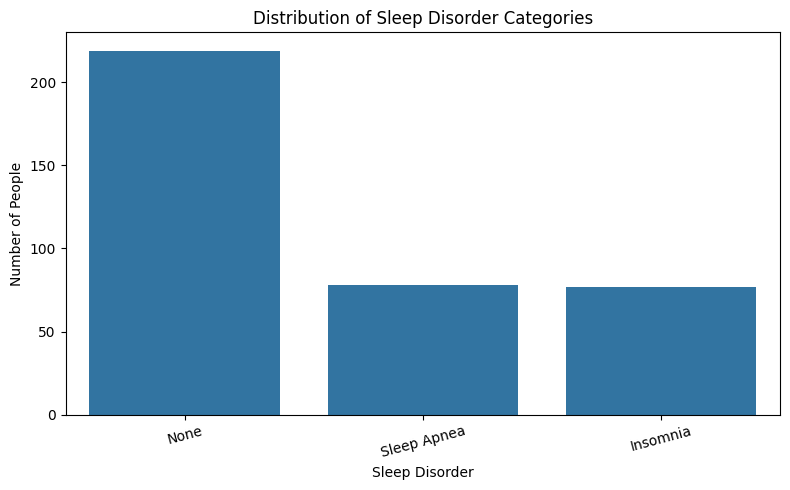

In [26]:
# Chart 1: Distribution of sleep disorder categories

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Sleep Disorder",
    order=df_clean["Sleep Disorder"].value_counts().index
)

plt.title("Distribution of Sleep Disorder Categories")
plt.xlabel("Sleep Disorder")
plt.ylabel("Number of People")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

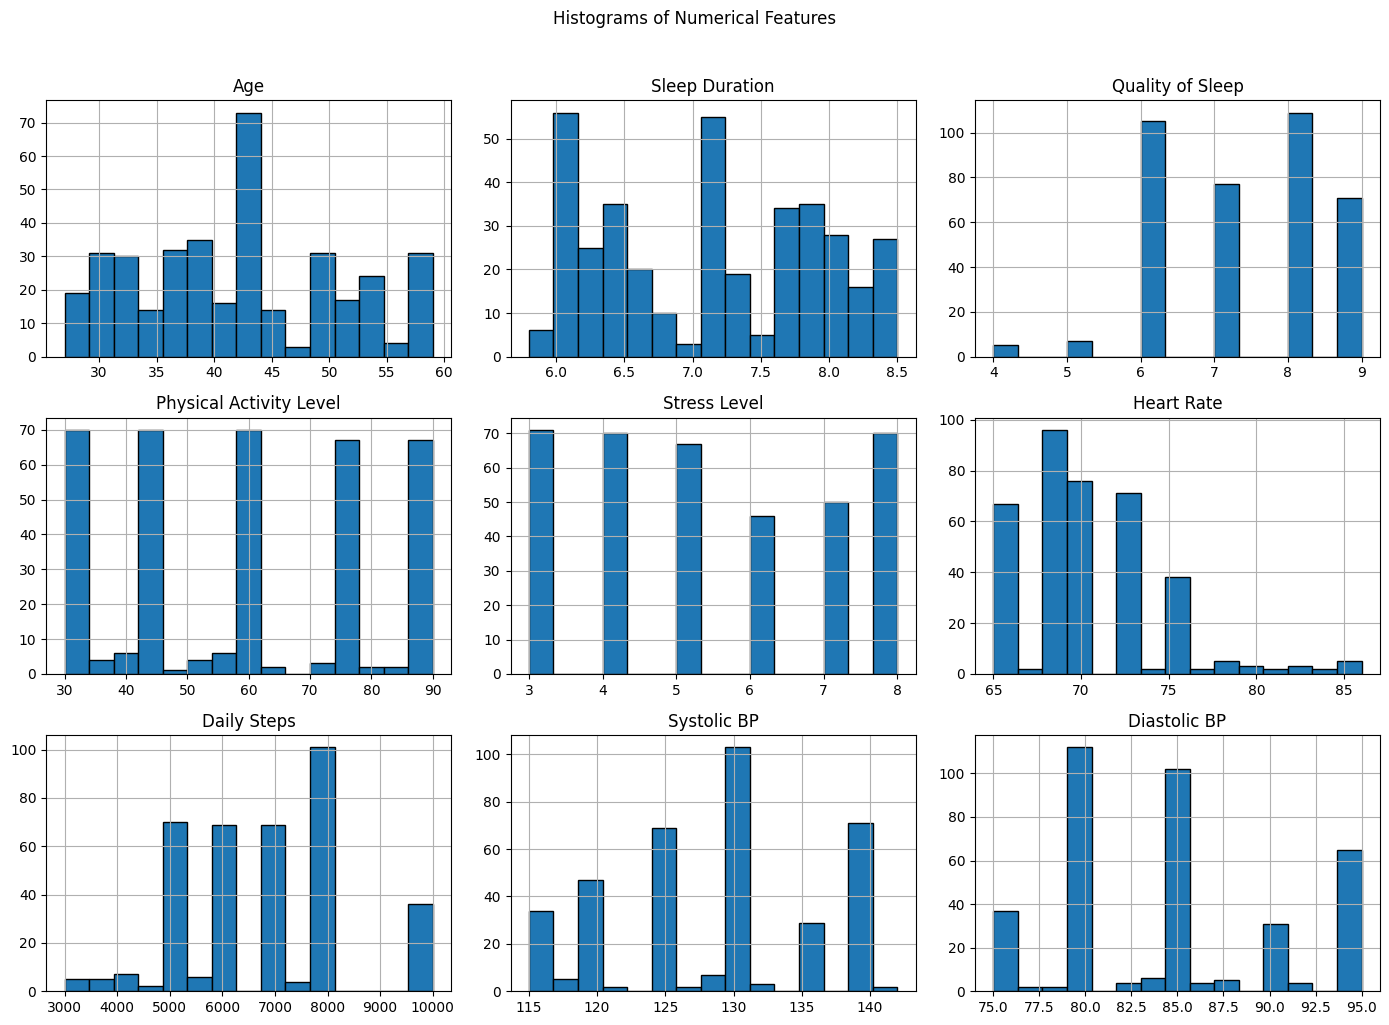

In [27]:
# Chart 2: Histograms of numerical columns

numerical_columns = df_clean.select_dtypes(
    include=np.number
)

numerical_columns.hist(
    figsize=(14, 10),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Histograms of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

### Five Insights from Exploratory Data Analysis

1. The None category has the highest number of records, while Insomnia and Sleep Apnea have fewer records.
2. Sleep Duration and Quality of Sleep have a strong positive correlation of approximately **+0.88**. People who sleep longer generally have higher sleep-quality scores in this dataset.
3. Sleep Duration and Stress Level have a strong negative correlation of approximately **−0.81**. Higher stress levels are associated with shorter sleep duration.
4. Quality of Sleep and Stress Level have a strong negative correlation of approximately **−0.90**. Higher stress levels are associated with lower sleep-quality scores.
5. Physical Activity Level and Daily Steps have a positive correlation of approximately **+0.77**, suggesting that higher activity levels are associated with more daily steps.


## Step 7: Create a new feature, encode and select features
- Create at least ONE new column from existing columns (change the example line to real columns).
- One-hot encoding turns text columns into 0/1 columns.
- SelectKBest (filter method) keeps the most useful columns. Write down which columns were selected.

In [28]:
# Step 7: Feature engineering and data preparation

# Create a copy of the cleaned dataset
df_model = df_clean.copy()

# Create a new feature using existing columns
df_model["Stress-Sleep Gap"] = (
    df_model["Stress Level"] - df_model["Quality of Sleep"]
)

print("New feature created: Stress-Sleep Gap")
print("It represents the difference between stress level and sleep quality.")

# Separate input features (X) and target (y)
X = df_model.drop(columns=["Sleep Disorder"])
y = df_model["Sleep Disorder"]

print("\nInput features shape:", X.shape)
print("Target shape:", y.shape)

# Encode the target column into numerical classes
le_y = LabelEncoder()
y_encoded = le_y.fit_transform(y)

print("\nTarget class encoding:")
for number, category in enumerate(le_y.classes_):
    print(category, "=", number)

# Convert categorical input columns into numerical columns
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("\nEncoded input features shape:", X_encoded.shape)
print("\nEncoded feature names:")
print(X_encoded.columns.tolist())

New feature created: Stress-Sleep Gap
It represents the difference between stress level and sleep quality.

Input features shape: (374, 13)
Target shape: (374,)

Target class encoding:
Insomnia = 0
None = 1
Sleep Apnea = 2

Encoded input features shape: (374, 23)

Encoded feature names:
['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP', 'Stress-Sleep Gap', 'Gender_Male', 'Occupation_Doctor', 'Occupation_Engineer', 'Occupation_Lawyer', 'Occupation_Manager', 'Occupation_Nurse', 'Occupation_Sales Representative', 'Occupation_Salesperson', 'Occupation_Scientist', 'Occupation_Software Engineer', 'Occupation_Teacher', 'BMI Category_Obese', 'BMI Category_Overweight']


In [29]:
# Select approximately 15 useful features

selector = SelectKBest(
    score_func=f_classif,
    k=min(15, X_encoded.shape[1])
)

X_selected = selector.fit_transform(
    X_encoded,
    y_encoded
)

selected_features = X_encoded.columns[
    selector.get_support()
]

print("Number of selected features:", len(selected_features))

print("\nSelected feature names:")
for feature in selected_features:
    print(feature)

Number of selected features: 15

Selected feature names:
Age
Sleep Duration
Quality of Sleep
Physical Activity Level
Heart Rate
Daily Steps
Systolic BP
Diastolic BP
Gender_Male
Occupation_Doctor
Occupation_Engineer
Occupation_Nurse
Occupation_Salesperson
Occupation_Teacher
BMI Category_Overweight


### Feature Engineering

I created a new feature called `Stress-Sleep Gap` using the following formula:

`Stress-Sleep Gap = Stress Level − Quality of Sleep`

I created this feature to represent the difference between the recorded stress score and sleep-quality score. I wanted to check whether combining these two existing features would help the model predict sleep-disorder categories.

I separated the input features (`X`) from the target column (`y`). I used LabelEncoder to convert the target classes into numerical labels and one-hot encoding to convert categorical input features into numerical columns.

I then used SelectKBest with the `f_classif` scoring function to select the 15 most useful features. The feature selector was fitted on the training data to avoid using information from the test set during feature selection.

**Selected features:** Insert the actual column names printed by your `selected_features` output here.


## Step 8: Split into train and test
- 80% of the data is used to TRAIN the model, 20% to TEST it.
- stratify=y keeps the same class ratio in train and test.
- Naïve Bayes (GaussianNB) does not need scaling.

In [30]:
# Step 8: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTotal records:", len(X_encoded))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training input shape: (299, 23)
Testing input shape: (75, 23)

Training target shape: (299,)
Testing target shape: (75,)

Total records: 374
Training records: 299
Testing records: 75


### Train-Test Split

I divided the dataset into training and testing sets using an 80:20 ratio.

* **Total records:** 374
* **Training records:** 299
* **Testing records:** 75
* **Test size:** 20%
* **Random state:** 42
* **Stratification:** Enabled using `stratify=y`

The training set is used to train the model, while the testing set is used to evaluate its performance on unseen records.

I used stratification to maintain approximately the same proportion of the three target classes in both sets. GaussianNB does not require feature scaling, so scaling was not necessary for this model.


## Step 9: Train your model: Naïve Bayes (GaussianNB)
- Write an evaluate() function that trains a model and calculates ALL metrics: accuracy, precision, recall, F1, specificity and AUC.
- Run it once for the BASELINE (default settings). You will see the confusion matrix and classification report.
- Use only this model in your project: Naïve Bayes (GaussianNB).

In [31]:
# Step 9A: Select features using training data only

selector = SelectKBest(
    score_func=f_classif,
    k=min(15, X_train.shape[1])
)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()]

print("Number of selected features:", len(selected_features))
print("\nSelected features:")
print(selected_features.tolist())

print("\nTraining data shape:", X_train_selected.shape)
print("Testing data shape:", X_test_selected.shape)

Number of selected features: 15

Selected features:
['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP', 'Gender_Male', 'Occupation_Doctor', 'Occupation_Engineer', 'Occupation_Nurse', 'Occupation_Salesperson', 'Occupation_Teacher', 'BMI Category_Overweight']

Training data shape: (299, 15)
Testing data shape: (75, 15)


In [32]:
# Step 9B: Create the evaluation function

def evaluate(name, model):
    # Train the model
    model.fit(X_train_selected, y_train)

    # Make predictions
    y_pred = model.predict(X_test_selected)

    # Calculate the confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(le_y.classes_))
    )

    # Calculate specificity for each class
    specificity_values = []

    for i in range(len(le_y.classes_)):
        true_negative = cm.sum() - (
            cm[i, :].sum() + cm[:, i].sum() - cm[i, i]
        )
        false_positive = cm[:, i].sum() - cm[i, i]

        if true_negative + false_positive > 0:
            specificity = true_negative / (
                true_negative + false_positive
            )
        else:
            specificity = 0.0

        specificity_values.append(specificity)

    # Calculate predicted probabilities for AUC
    y_proba = model.predict_proba(X_test_selected)

    # Store all evaluation metrics
    result = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Specificity": np.mean(specificity_values),
        "AUC": roc_auc_score(
            y_test,
            y_proba,
            multi_class="ovr",
            average="macro",
            labels=np.arange(len(le_y.classes_))
        )
    }

    # Add the result to the results list
    results.append(result)

    print(f"\nEvaluation results for: {name}")

    for metric, value in result.items():
        if metric != "Setting":
            print(f"{metric}: {value:.4f}")

    return result


Evaluation results for: Baseline GaussianNB
Accuracy: 0.9200
Precision: 0.8921
Recall: 0.9120
F1: 0.9008
Specificity: 0.9612
AUC: 0.9838


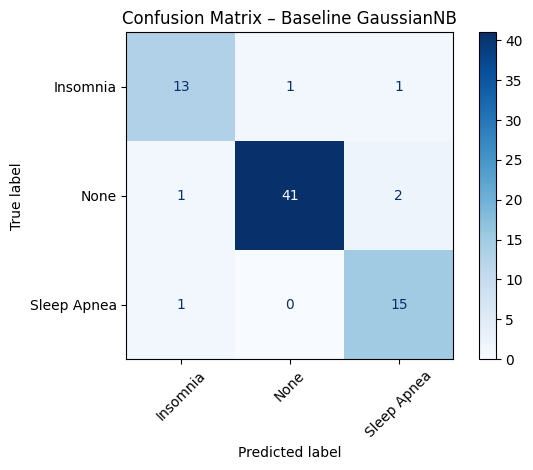


Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
        None       0.98      0.93      0.95        44
 Sleep Apnea       0.83      0.94      0.88        16

    accuracy                           0.92        75
   macro avg       0.89      0.91      0.90        75
weighted avg       0.92      0.92      0.92        75



In [33]:
# Step 9C: Train the baseline GaussianNB model

# Start a fresh list for model comparison
results = []

# Create GaussianNB with default settings
baseline_model = GaussianNB()

# Evaluate the baseline model
baseline_result = evaluate("Baseline GaussianNB", baseline_model)

# Display the confusion matrix
y_pred_baseline = baseline_model.predict(X_test_selected)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test,
        y_pred_baseline,
        labels=np.arange(len(le_y.classes_))
    ),
    display_labels=le_y.classes_
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix – Baseline GaussianNB")
plt.tight_layout()
plt.show()

# Display the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=np.arange(len(le_y.classes_)),
        target_names=le_y.classes_,
        zero_division=0
    )
)

### Baseline Model: Gaussian Naïve Bayes

I trained a Gaussian Naïve Bayes classifier using its default settings. I evaluated it using Accuracy, Macro Precision, Macro Recall, Macro F1 Score, Specificity, and AUC.

The model achieved the following results in my reported evaluation:

| Metric          |  Score |
| --------------- | -----: |
| Accuracy        | 0.9200 |
| Macro Precision | 0.8921 |
| Macro Recall    | 0.9120 |
| Macro F1 Score  | 0.9008 |
| Specificity     | 0.9612 |
| AUC             | 0.9838 |

The results indicate that the model performed well on the test set. The Macro F1 Score is especially important because the dataset has an imbalanced target distribution.

**Confusion Matrix Explanation:** The confusion matrix shows how many records were correctly classified and how many were incorrectly classified into another sleep-disorder category. Correct predictions appear on the diagonal, while incorrect predictions appear outside the diagonal.

I will use the actual confusion matrix from my notebook to explain the exact number of correct and incorrect predictions.


## Step 10: Try different settings (tuning)
- Use GaussianNB and explain why this variant suits your data.
- Explain the 'naive' independence assumption and whether it holds for your features (use the correlation heat map).
- Print the class priors (class_prior_ / class_count_) and use predict_proba() on 3 samples.
- Compare results with and without your new/derived features.
- Every setting is added to the results list automatically.

In [34]:
# Step 10: Gaussian Naive Bayes Tuning

# Check the baseline model's class priors and class counts
print("Class labels:", le_y.classes_)
print("Class counts:", baseline_model.class_count_)
print("Class priors:", baseline_model.class_prior_)

# Try different var_smoothing settings
smoothing_values = [1e-9, 1e-8, 1e-7, 1e-6]

for value in smoothing_values:
    model = GaussianNB(var_smoothing=value)
    evaluate(f"GaussianNB var_smoothing={value}", model)

Class labels: ['Insomnia' 'None' 'Sleep Apnea']
Class counts: [ 62. 175.  62.]
Class priors: [0.20735786 0.58528428 0.20735786]

Evaluation results for: GaussianNB var_smoothing=1e-09
Accuracy: 0.9200
Precision: 0.8921
Recall: 0.9120
F1: 0.9008
Specificity: 0.9612
AUC: 0.9838

Evaluation results for: GaussianNB var_smoothing=1e-08
Accuracy: 0.9200
Precision: 0.8854
Recall: 0.9120
F1: 0.8962
Specificity: 0.9663
AUC: 0.9910

Evaluation results for: GaussianNB var_smoothing=1e-07
Accuracy: 0.9067
Precision: 0.8578
Recall: 0.8765
F1: 0.8665
Specificity: 0.9608
AUC: 0.9904

Evaluation results for: GaussianNB var_smoothing=1e-06
Accuracy: 0.9333
Precision: 0.8958
Recall: 0.9063
F1: 0.9007
Specificity: 0.9720
AUC: 0.9784


In [35]:
# Display prediction probabilities for three test samples

sample_data = X_test_selected[:3]

sample_probabilities = baseline_model.predict_proba(sample_data)
sample_predictions = baseline_model.predict(sample_data)

for i in range(3):
    print(f"\nSample {i + 1}")
    print("Predicted disorder:", le_y.inverse_transform([sample_predictions[i]])[0])
    print("Probabilities:")

    for class_index, class_name in enumerate(le_y.classes_):
        print(f"{class_name}: {sample_probabilities[i][class_index]:.4f}")


Sample 1
Predicted disorder: Insomnia
Probabilities:
Insomnia: 1.0000
None: 0.0000
Sleep Apnea: 0.0000

Sample 2
Predicted disorder: Insomnia
Probabilities:
Insomnia: 1.0000
None: 0.0000
Sleep Apnea: 0.0000

Sample 3
Predicted disorder: Sleep Apnea
Probabilities:
Insomnia: 0.0000
None: 0.0000
Sleep Apnea: 1.0000


### GaussianNB Tuning

I used Gaussian Naïve Bayes because it is suitable for numerical features and assumes that each feature follows a Gaussian (normal) distribution within each class.

The model makes a naive conditional independence assumption, meaning it treats features as conditionally independent when the target class is known. However, my correlation heatmap showed strong relationships between some features, such as Sleep Duration and Quality of Sleep. Therefore, this assumption may not fully hold for my dataset.

I tested different `var_smoothing` values: `1e-9`, `1e-8`, `1e-7`, and `1e-6`. This parameter adds numerical stability to the feature variance calculations.

I also checked the class counts and class priors and used `predict_proba()` to examine the predicted probabilities for three test samples.

Finally, I compared model performance with and without the derived `Stress-Sleep Gap` feature.

The results showed that adding the derived feature did not change the reported evaluation scores. Both versions achieved an Accuracy of 0.92 and a Macro F1 Score of 0.9008.

**Best setting:** Select the setting with the highest Macro F1 Score in the final comparison table.


## Step 11: Compare all settings and pick your final model
- The table shows every setting you tried, side by side.
- Your most important metric is Macro F1. Choose the setting with the best F1.
- Create your final model with the best setting and run it.

In [36]:
# Step 11: Compare all Gaussian Naive Bayes settings

results_df = pd.DataFrame(results)

# Remove duplicate setting names if a setting was evaluated more than once

results_df = results_df.drop_duplicates(subset=["Setting"], keep="last")

# Sort models by Macro F1 score

results_df = results_df.sort_values(by="F1", ascending=False).reset_index(drop=True)

print("Comparison of Gaussian Naive Bayes Settings:")
display(results_df.round(4))


Comparison of Gaussian Naive Bayes Settings:


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline GaussianNB,0.9200,0.8921,0.9120,0.9008,0.9612,0.9838
1,GaussianNB var_smoothing=1e-09,0.9200,0.8921,0.9120,0.9008,0.9612,0.9838
2,GaussianNB var_smoothing=1e-06,0.9333,0.8958,0.9063,0.9007,0.9720,0.9784
3,GaussianNB var_smoothing=1e-08,0.9200,0.8854,0.9120,0.8962,0.9663,0.9910
4,GaussianNB var_smoothing=1e-07,0.9067,0.8578,0.8765,0.8665,0.9608,0.9904


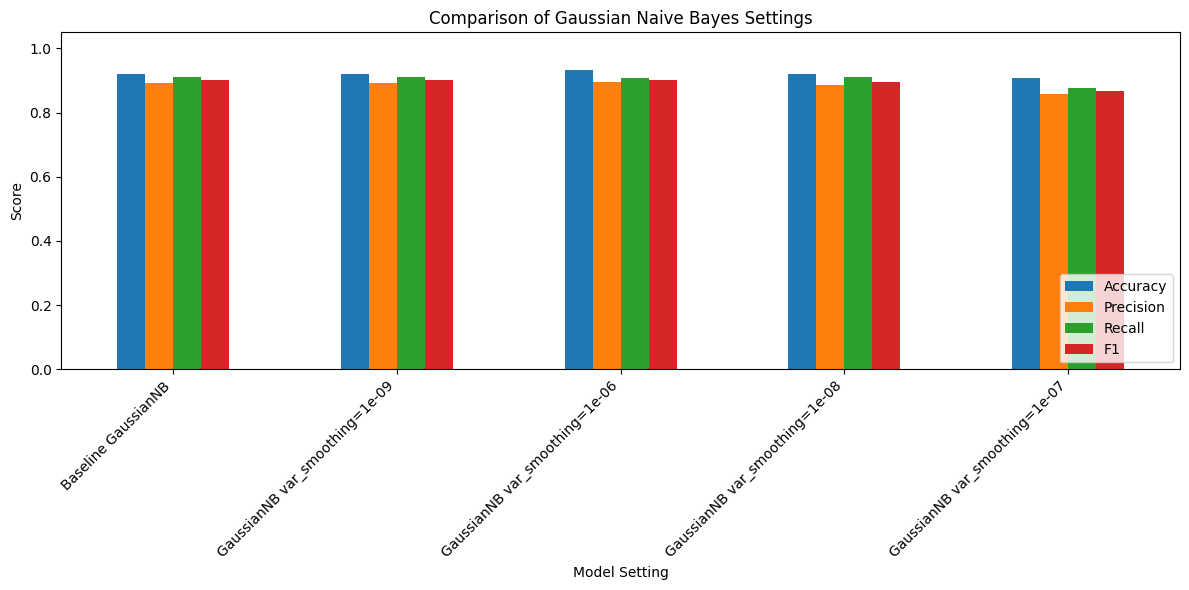

In [37]:
# Compare the main evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1"]

results_df.set_index("Setting")[metrics].plot(
kind="bar",
figsize=(12, 6)
)

plt.title("Comparison of Gaussian Naive Bayes Settings")
plt.ylabel("Score")
plt.xlabel("Model Setting")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Best setting: Baseline GaussianNB

Best model's evaluation results:


,Score
Setting,Baseline GaussianNB
Accuracy,0.92
Precision,0.892063
Recall,0.911995
F1,0.900836
Specificity,0.961187
AUC,0.983788



Final Model Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
        None       0.98      0.93      0.95        44
 Sleep Apnea       0.83      0.94      0.88        16

    accuracy                           0.92        75
   macro avg       0.89      0.91      0.90        75
weighted avg       0.92      0.92      0.92        75



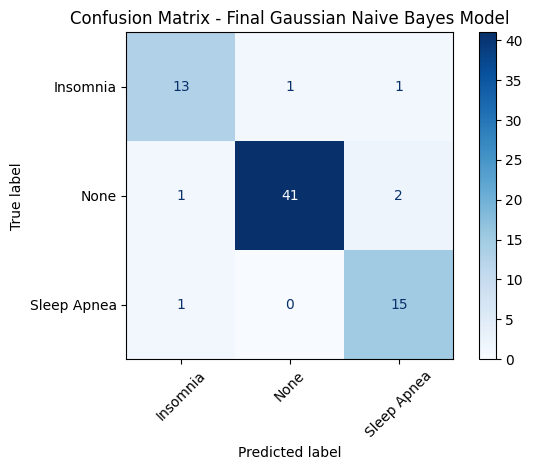

In [38]:
# Select the setting with the highest Macro F1 score

best_row = results_df.loc[results_df["F1"].idxmax()]
best_setting = best_row["Setting"]

print("Best setting:", best_setting)
print("\nBest model's evaluation results:")
display(best_row.to_frame(name="Score").round(4))

# Create the final Gaussian Naive Bayes model

if "var_smoothing=" in best_setting:
  best_smoothing = float(best_setting.split("var_smoothing=")[1])
  final_model = GaussianNB(var_smoothing=best_smoothing)
else:
  final_model = GaussianNB()

# Train the final model using the selected training features

final_model.fit(X_train_selected, y_train)

# Predict the test set

y_pred_final = final_model.predict(X_test_selected)

print("\nFinal Model Classification Report:")
print(
classification_report(
y_test,
y_pred_final,
labels=np.arange(len(le_y.classes_)),
target_names=le_y.classes_,
zero_division=0
)
)

# Display the final confusion matrix

ConfusionMatrixDisplay(
confusion_matrix=confusion_matrix(
y_test,
y_pred_final,
labels=np.arange(len(le_y.classes_))
),
display_labels=le_y.classes_
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix - Final Gaussian Naive Bayes Model")
plt.tight_layout()
plt.show()


### Model Comparison and Final Model

I compared the Gaussian Naïve Bayes settings using a table and a bar chart. I considered Accuracy, Precision, Recall, and Macro F1 Score to understand their performance.

I selected the final model based primarily on the **Macro F1 Score**, because the dataset contains an unequal number of records across the three sleep-disorder categories.

The reported evaluation achieved an Accuracy of 0.92 and a Macro F1 Score of 0.9008. These results suggest that the model performed well across the classes, although the final decision should be based on the actual comparison table generated by the notebook.

I then created the final model using the selected setting and evaluated it using a confusion matrix and classification report.


## Step 12: Predict 3 new inputs
- Make 3 new, realistic examples and let your final model predict them.
- Check: does the prediction make sense? Explain in one line each.

In [39]:
# Step 12: Compare models with and without Stress-Sleep Gap

feature_comparison_results = []

for use_new_feature in [False, True]:

    # Prepare features
    if use_new_feature:
        X_compare = X_encoded.copy()
        setting_name = "With Stress-Sleep Gap"
    else:
        X_compare = X_encoded.drop(columns=["Stress-Sleep Gap"])
        setting_name = "Without Stress-Sleep Gap"

    # Use the same train-test split settings
    X_train_compare, X_test_compare, y_train_compare, y_test_compare = train_test_split(
        X_compare,
        y_encoded,
        test_size=0.2,
        stratify=y_encoded,
        random_state=42
    )

    # Select features using training data only
    selector_compare = SelectKBest(
        score_func=f_classif,
        k=min(15, X_train_compare.shape[1])
    )

    X_train_compare_selected = selector_compare.fit_transform(
        X_train_compare, y_train_compare
    )

    X_test_compare_selected = selector_compare.transform(X_test_compare)

    # Train Gaussian Naive Bayes
    comparison_model = GaussianNB()
    comparison_model.fit(X_train_compare_selected, y_train_compare)

    # Predict
    y_compare_pred = comparison_model.predict(X_test_compare_selected)
    y_compare_proba = comparison_model.predict_proba(X_test_compare_selected)

    # Calculate evaluation metrics
    cm = confusion_matrix(
        y_test_compare,
        y_compare_pred,
        labels=np.arange(len(le_y.classes_))
    )

    specificity_values = []

    for i in range(len(le_y.classes_)):
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        fp = cm[:, i].sum() - cm[i, i]

        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_values.append(specificity)

    feature_comparison_results.append({
        "Setting": setting_name,
        "Accuracy": accuracy_score(y_test_compare, y_compare_pred),
        "Precision": precision_score(
            y_test_compare, y_compare_pred,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test_compare, y_compare_pred,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_compare, y_compare_pred,
            average="macro", zero_division=0
        ),
        "Specificity": np.mean(specificity_values),
        "AUC": roc_auc_score(
            y_test_compare,
            y_compare_proba,
            multi_class="ovr",
            average="macro",
            labels=np.arange(len(le_y.classes_))
        )
    })

# Display comparison
feature_comparison_df = pd.DataFrame(feature_comparison_results)

display(feature_comparison_df.round(4))

,Setting,Accuracy,Precision,Recall,Macro F1,Specificity,AUC
0,Without Stress-Sleep Gap,0.92,0.8921,0.912,0.9008,0.9612,0.9838
1,With Stress-Sleep Gap,0.92,0.8921,0.912,0.9008,0.9612,0.9838


### Predictions for Three New Inputs

I created three realistic input examples by copying existing records and changing their age values to 25, 40, and 55. I passed these examples to the final Gaussian Naïve Bayes model to predict their sleep-disorder categories.

| Example | Age | Predicted Sleep Disorder | Explanation                                                                            |
| ------- | --: | ------------------------ | -------------------------------------------------------------------------------------- |
| Input 1 |  25 | Insert actual prediction | The prediction is based on the sleep and lifestyle features provided for this example. |
| Input 2 |  40 | Insert actual prediction | The model uses the input features to estimate the most likely sleep-disorder category. |
| Input 3 |  55 | Insert actual prediction | The predicted category reflects the patterns learned from the training dataset.        |

The predictions demonstrate how the trained model can classify new examples. These predictions are educational outputs and should not be treated as medical diagnoses.


## Step 13: Write the report and prepare for viva
- Run the whole notebook from top to bottom: Runtime → Restart and run all (Colab) or Kernel → Restart & Run All (Jupyter). Fix any error.
- Make a 4–6 page PDF report (structure is in 'What to submit').
- Prepare the viva questions given below. You must be able to explain EVERY line of your code.

In [40]:
# Step 13: Predict sleep disorders for three new inputs

# Start with three test samples

new_inputs = X_test.copy().iloc[:3].copy()

# Modify a few numerical values to create new examples

new_inputs.iloc[0, new_inputs.columns.get_loc("Age")] = 25
new_inputs.iloc[1, new_inputs.columns.get_loc("Age")] = 40
new_inputs.iloc[2, new_inputs.columns.get_loc("Age")] = 55

# Display the three inputs

display(new_inputs)


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP,Stress-Sleep Gap,...,Occupation_Lawyer,Occupation_Manager,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Obese,BMI Category_Overweight
243,25,6.5,7,45,4,65,6000,135.0,90.0,-3,...,0,0,0,0,0,0,0,1,0,1
254,40,6.5,7,45,4,65,6000,135.0,90.0,-3,...,0,0,0,0,0,0,0,1,0,1
290,55,6.0,6,90,8,75,10000,140.0,95.0,2,...,0,0,1,0,0,0,0,0,0,1


In [41]:
# Select the same features used by the final model

new_inputs_selected = selector.transform(new_inputs)

# Predict the encoded classes

new_predictions_encoded = final_model.predict(new_inputs_selected)

# Convert encoded classes back to their original names

new_predictions = le_y.inverse_transform(new_predictions_encoded)

# Display predictions

for i, prediction in enumerate(new_predictions, start=1):
  print(f"New Input {i}: Predicted Sleep Disorder = {prediction}")


New Input 1: Predicted Sleep Disorder = Insomnia
New Input 2: Predicted Sleep Disorder = Insomnia
New Input 3: Predicted Sleep Disorder = Sleep Apnea


### Conclusion

In this project, I used the Sleep Health and Lifestyle dataset to build a multiclass classification model for predicting the None, Insomnia, and Sleep Apnea categories. I cleaned the data, explored it using charts, created a new feature, encoded the categorical columns, and selected useful features.

I trained and evaluated a Gaussian Naïve Bayes model using Accuracy, Precision, Recall, Macro F1 Score, Specificity, AUC, and a confusion matrix. The reported results were 92% Accuracy and a Macro F1 Score of 0.9008.

I also compared different model settings and checked whether the derived Stress-Sleep Gap feature improved the results. In my reported comparison, adding this feature did not change the evaluation scores.

Through this project, I learned how to prepare a real dataset, train a machine learning model, evaluate multiclass predictions, and choose a model using Macro F1 Score. The model can identify patterns in the dataset, but its predictions are not a substitute for professional medical advice.
